# mizuRoute vs. USGS Observed Streamflow -- Monthly Comparison
Uses the `flow_multi_agency_all_meta.csv` crosswalk (gauge -> merit_reach_id) validated earlier, pulls monthly mizuRoute `RoutedRunoff`, compares against the local combined multi-agency observed streamflow dataset, and computes NSE/KGE per gauge.

**Fixed in this version (see inline notes marked `# FIX:`):**
1. `reachID` in the mizuRoute output carries a spurious `time` dimension even though it's physically constant. The original per-gauge lookup (`np.where(ds_rof["reachID"].values == reach_id)[0]`) silently indexed into the *time* axis instead of the *seg* axis, so every gauge comparison was evaluating segment 0 regardless of which reach was requested. Fixed by slicing `reachID` to a single timestep once, up front.
2. The local combined obs file (`flow_multi_agency_*.nc`, 1965-2024) was loaded but never actually used -- the notebook queried the live USGS NWIS web API every time instead, which is slower and depends on outbound network access from a compute node. Now the local file is used first, with the live API as an optional fallback for sites it doesn't cover.
3. mizuRoute's monthly output is timestamped mid-month (e.g. day 16) while the observed monthly file uses a different day-of-month convention (commonly month-start). Merging on exact timestamps silently dropped nearly every month even when both series covered the same period. Both series are now normalized to a calendar-month `Period` before merging, and the "not enough overlap" failure branch now prints each series' actual length/date range so a genuine data gap is distinguishable from an alignment bug.
4. The local *monthly* obs file (`flow_multi_agency_..._month.nc`) only covers 29 of the 2311 crosswalk sites -- not usable as the primary observed source. The *daily* file covers all 2311 (an exact match to the crosswalk), so that's now the primary source, resampled to monthly here instead of relying on the mostly-empty monthly file. The live USGS API remains a fallback for anything not in the daily file.
5. Added Section 9: search the crosswalk by river name (e.g. Missouri, Columbia, Colorado) -- plus a HUC02-based lookup, since name matching alone pulled in the wrong river for "Colorado" (Texas's Colorado River, not the western Colorado) and missed the real Columbia River gauges entirely.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.dates as mdates
import geopandas as gpd
import glob

In [2]:
# Exploratory / not wired into the eval pipeline below -- kept for reference.
gdf_catch = gpd.read_file("/glade/campaign/ral/hap/mizukami/work/data/MERIT_hydro/v1/nldas/nldas_MERIT_v1_catch.gpkg")
print(gdf_catch.columns.tolist())
print(gdf_catch.head())
print(f"Number of catchments: {len(gdf_catch)}")

['hruid', 'isHill', 'pfaf', 'area', 'geometry']
      hruid  isHill          pfaf          area  \
0  73018513       0  L0C58R211421  6.727792e+07   
1  78013837       0   L0C76R95357  3.143858e+07   
2  72043923       0    L0C4R27794  6.025465e+07   
3  73007313       0    L0C5518R23  2.702562e+07   
4  73013853       0    L0C556R814  3.614764e+07   

                                            geometry  
0  MULTIPOLYGON (((-88.08042 31.30208, -88.07958 ...  
1  MULTIPOLYGON (((-116.46792 48.93958, -116.4662...  
2  MULTIPOLYGON (((-79.24292 46.76125, -79.24125 ...  
3  MULTIPOLYGON (((-76.77375 38.46625, -76.77292 ...  
4  MULTIPOLYGON (((-81.73708 34.61125, -81.73542 ...  
Number of catchments: 227247


In [3]:
CROSSWALK_CSV = "<path_to_gauge_metadata>/route/extract_seg/ancillary_data/flow_multi_agency_all_meta.csv"
MIZUROUTE_DIR = "/glade/derecho/scratch/mozhgana/archive/control/rof/hist/"
MIZUROUTE_PATTERN = "control.mizuroute.h.*.nc"

# FIX: these were previously duplicated (opened again inside a later cell
# and again inside get_usgs_monthly). Defined once here.
OBS_DAILY_PATH = "<path_to_streamflow_tseries>/flow_multi_agency_1965-10-01_2024-09-30.nc"
OBS_MONTHLY_PATH = "<path_to_streamflow_tseries>/flow_multi_agency_1965-10_2024-09_month.nc"

OUTPUT_DIR = "streamflow_eval_plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [4]:
ds_obs_daily = xr.open_dataset(OBS_DAILY_PATH, decode_times=True)
ds_obs_monthly = xr.open_dataset(OBS_MONTHLY_PATH, decode_times=True)

obs_daily_sites = set(ds_obs_daily["site"].values.astype(int))
obs_monthly_sites = set(ds_obs_monthly["site"].values.astype(int))
print(f"Local obs file covers {len(obs_monthly_sites)} sites (monthly), {len(obs_daily_sites)} sites (daily)")

Local obs file covers 29 sites (monthly), 2311 sites (daily)


In [5]:
ds_obs_daily

<xarray.Dataset> Size: 399MB
Dimensions:     (time: 21550, site: 2311)
Coordinates:
  * time        (time) datetime64[ns] 172kB 1965-10-01 1965-10-02 ... 2024-09-30
  * site        (site) int64 18kB 5376000 3538225 5513000 ... 13336500 13258500
Data variables:
    streamflow  (time, site) float64 398MB ...
    site_str    (site) <U10 92kB ...
    agency      (site) <U5 46kB ...

In [6]:
# FIX (diagnostic, new): confirm the actual flow variable name and units in
# the local obs file before trusting values pulled from it. The original
# notebook never inspected this -- it's easy to silently mix up units
# (cfs vs m3/s) or grab the wrong variable if there's more than one.
print("Data variables in ds_obs_daily:", list(ds_obs_daily.data_vars))
for v in ds_obs_daily.data_vars:
    print(f"  {v}: dims={ds_obs_daily[v].dims}, units={ds_obs_daily[v].attrs.get('units', '???')}")
print()
print("Data variables in ds_obs_monthly:", list(ds_obs_monthly.data_vars))
for v in ds_obs_monthly.data_vars:
    print(f"  {v}: dims={ds_obs_monthly[v].dims}, units={ds_obs_monthly[v].attrs.get('units', '???')}")

def _guess_flow_varname(ds):
    candidates = [v for v in ds.data_vars if v.lower() in
                  ("flow", "q", "discharge", "streamflow", "runoff")]
    if candidates:
        return candidates[0]
    if len(ds.data_vars) == 1:
        return list(ds.data_vars)[0]
    raise ValueError(
        f"Could not auto-detect the flow variable in ds_obs_monthly; "
        f"found {list(ds.data_vars)}. Set OBS_FLOW_VAR manually below."
    )

# FIX: the monthly file only covers 29 of 2311 crosswalk sites (confirmed
# via obs_monthly_sites above) -- the daily file, which covers all 2311, is
# the actual primary observed source (resampled to monthly in
# get_usgs_monthly below). OBS_FLOW_VAR is detected once here and used for
# both, since both files share the same variable name.
OBS_FLOW_VAR = _guess_flow_varname(ds_obs_daily)
print(f"\nUsing '{OBS_FLOW_VAR}' as the flow variable.")
print(f"Units: {ds_obs_daily[OBS_FLOW_VAR].attrs.get('units', 'NOT SET -- confirm manually before trusting comparisons')}")

Data variables in ds_obs_daily: ['streamflow', 'site_str', 'agency']
  streamflow: dims=('time', 'site'), units=m3/s
  site_str: dims=('site',), units=???
  agency: dims=('site',), units=???

Data variables in ds_obs_monthly: ['streamflow', 'site_str', 'agency']
  streamflow: dims=('time', 'site'), units=m3/s
  site_str: dims=('site',), units=???
  agency: dims=('site',), units=???

Using 'streamflow' as the flow variable.
Units: m3/s


In [7]:
region='18'
shp_file   = f"<path_to_gauge_metadata>/huc2/multi_agency_{region}_site.gpkg"
gdf = gpd.read_file(shp_file)
df_map=gdf.copy()
df_map.info()

df_map["gage_type"] = "interior"   #These are mid-network gauges. depend on upstream choices, must be evaluated after all their contributors are fixed

df_map.loc[
    (df_map["site_rank"] == 0) & (df_map["down_site_ID"].isna()),
    "gage_type"
] = "single_basin"    #Just choose best ensemble and fix HUC12s -----> No routing dependency.

df_map.loc[
    (df_map["site_rank"] == 0) & (~df_map["down_site_ID"].isna()),
    "gage_type"
] = "headwater" # have no upstream contributors, They start the sequential chain for each basin.
# (rest of gage_type classification logic as before -- unused by the eval
# pipeline below, kept for reference / other analysis)

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   Station ID                    105 non-null    object  
 1   GAGE_ID                       105 non-null    int64   
 2   Longitude                     105 non-null    float64 
 3   Latitude                      105 non-null    float64 
 4   Elev                          92 non-null     float64 
 5   area_sqkm                     105 non-null    float64 
 6   Is_CAMELS                     105 non-null    object  
 7   RFC                           105 non-null    object  
 8   NWS_Loc_ID                    105 non-null    object  
 9   Long_Name                     105 non-null    object  
 10  merit_reach_id                105 non-null    int64   
 11  hru_id                        104 non-null    float64 
 12  area_merit_sqkm               105 non-null

## 2. Load gauge crosswalk

In [8]:
df_gauges = pd.read_csv(CROSSWALK_CSV)
df_gauges["merit_reach_id"] = df_gauges["merit_reach_id"].astype(int)
df_gauges["Latitude"] = df_gauges["Latitude"].astype(float)
df_gauges["Longitude"] = df_gauges["Longitude"].astype(float)
print(f"Loaded {len(df_gauges)} gauges")
df_gauges[["Station ID", "GAGE_ID", "Long_Name", "merit_reach_id", "Latitude", "Longitude"]].head()

Loaded 2311 gauges


,Station ID,GAGE_ID,Long_Name,merit_reach_id,Latitude,Longitude
0,01013500,1013500,Fish River Near Fort Kent ME,72040863,47.237500,-68.582778
1,01021480,1021480,Old Stream Near Wesley ME,73001405,44.936944,-67.736111
2,01022260,1022260,Pleasant River Near Epping ME,73001339,44.697778,-67.787222
3,01022500,1022500,Narraguagus River At Cherryfield ME,73000670,44.608056,-67.935278
4,01027200,1027200,North Branch Penobscot River Near Pittston Far...,73000125,45.935278,-69.993611


## 3. Load mizuRoute monthly output (all years)

In [9]:
files_rof = sorted(glob.glob(MIZUROUTE_DIR + MIZUROUTE_PATTERN))
print(f"Found {len(files_rof)} monthly mizuRoute files")
print(files_rof[0], "...", files_rof[-1])

def _keep_rof_fields(ds):
    keep = [v for v in ["RoutedRunoff", "reachID"] if v in ds.variables]
    return ds[keep]

ds_rof = xr.open_mfdataset(
    files_rof,
    combine="nested",
    concat_dim="time",
    decode_times=True,
    parallel=True,
    preprocess=_keep_rof_fields,
)

# FIX (critical): reachID has dims ('time','seg') even though it's constant
# across time. Slice to a single timestep ONCE here, rather than repeatedly
# comparing the full 2D array inside a per-gauge lookup function -- doing
# that made np.where return the wrong axis's indices (see helper functions
# section below for what this was silently breaking).
reach_id_1d = ds_rof["reachID"].isel(time=0).compute().values.astype(int)
print(f"reach_id_1d: {len(reach_id_1d)} reaches (should match n_reaches in ds_rof)")

ds_rof

Found 465 monthly mizuRoute files
/glade/derecho/scratch/mozhgana/archive/control/rof/hist/control.mizuroute.h.1980-01.nc ... /glade/derecho/scratch/mozhgana/archive/control/rof/hist/control.mizuroute.h.2018-09.nc
reach_id_1d: 227247 reaches (should match n_reaches in ds_rof)


/glade/derecho/scratch/mozhgana/tmp/ipykernel_57418/1192705840.py:9: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_rof = xr.open_mfdataset(


<xarray.Dataset> Size: 845MB
Dimensions:       (time: 465, seg: 227247)
Coordinates:
  * time          (time) object 4kB 1980-01-16 12:00:00 ... 2018-09-16 00:00:00
Dimensions without coordinates: seg
Data variables:
    RoutedRunoff  (time, seg) float32 423MB dask.array<chunksize=(1, 227247), meta=np.ndarray>
    reachID       (time, seg) int32 423MB dask.array<chunksize=(1, 227247), meta=np.ndarray>
Attributes:
    mizuRoute-version:  ctsm5.4.049
    gitBranch:          undefined
    gitHash:            undefined

## 4. Helper functions: extract modeled series, pull observed, compute metrics

`get_modeled_monthly` now indexes against the pre-sliced `reach_id_1d` (fixed).
`get_usgs_monthly` now reads the local combined obs file first (fixed to
actually use `ds_obs_monthly`/`ds_obs_daily`, loaded once in Section 1), and
only falls back to a live USGS web query if a site isn't in the local file.

In [10]:
def get_modeled_monthly(reach_id):
    """Extract modeled monthly RoutedRunoff (m3/s) time series for a given reachID."""
    # FIX: was np.where(ds_rof["reachID"].values == reach_id)[0], which
    # indexed the wrong (time) axis because reachID is 2D (time, seg).
    # reach_id_1d is the correct, pre-sliced 1D (seg,) array.
    idx = np.where(reach_id_1d == reach_id)[0]
    if len(idx) == 0:
        return None
    series = ds_rof["RoutedRunoff"].isel(seg=idx[0]).to_series()
    # FIX: mizuRoute monthly output is timestamped mid-month (e.g. day 16),
    # while the observed monthly file uses a different day-of-month
    # convention (commonly month-start). Concatenating on exact timestamps
    # then silently drops nearly every month even when both series cover
    # the same period. Normalize to a calendar-month Period so alignment
    # doesn't depend on which day of the month either source stamps.
    series.index = pd.PeriodIndex(pd.to_datetime(series.index.astype(str)), freq="M")
    series.name = "modeled"
    return series


def get_usgs_monthly(gage_id, start_date, end_date):
    """Observed monthly streamflow (m3/s) for a gauge. Uses the local
    combined daily file first (covers all 2311 crosswalk sites -- the
    monthly variant of this file only covers 29 of them, so it's not a
    usable primary source), resampled to monthly; falls back to a live
    USGS NWIS query only if the site isn't in the local file at all."""
    site_id = int(gage_id)

    if site_id in obs_daily_sites:
        da = ds_obs_daily[OBS_FLOW_VAR].sel(site=site_id)
        daily = da.to_series().loc[start_date:end_date].dropna()
        if not daily.empty:
            series = daily.resample("MS").mean()
            series.name = "observed"
            # FIX: same month-alignment normalization as get_modeled_monthly.
            series.index = pd.PeriodIndex(series.index, freq="M")
            return series
        # fall through to live query if the local slice is empty for this period

    return _get_usgs_monthly_live(gage_id, start_date, end_date)


def _get_usgs_monthly_live(gage_id, start_date, end_date):
    """Fallback: live USGS NWIS query, only used if the local combined
    obs file doesn't cover this gauge/period."""
    site_no = str(gage_id).zfill(8)
    url = (f"https://waterservices.usgs.gov/nwis/dv/?format=json"
           f"&sites={site_no}&startDT={start_date}&endDT={end_date}"
           f"&parameterCd=00060&siteStatus=all")
    try:
        df = pd.read_json(url)
        ts = df["value"]["timeSeries"]
        if len(ts) == 0:
            return None
        vals = ts[0]["values"][0]["value"]
        obs = pd.DataFrame(vals)
        obs["dateTime"] = pd.to_datetime(obs["dateTime"]).dt.tz_localize(None)
        obs["value"] = pd.to_numeric(obs["value"], errors="coerce") * 0.0283168  # cfs -> m3/s
        obs = obs.set_index("dateTime")["value"]
        obs_monthly = obs.resample("MS").mean()
        obs_monthly.name = "observed"
        # FIX: same month-alignment normalization.
        obs_monthly.index = pd.PeriodIndex(obs_monthly.index, freq="M")
        return obs_monthly
    except Exception as e:
        print(f"  USGS live fetch failed for site {site_no}: {e}")
        return None


def nse(obs, sim):
    return 1 - ((obs - sim) ** 2).sum() / ((obs - obs.mean()) ** 2).sum()


def kge(obs, sim):
    r = obs.corr(sim)
    alpha = sim.std() / obs.std()
    beta = sim.mean() / obs.mean()
    return 1 - ((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2) ** 0.5

## 5. Select gauges to evaluate
Edit `SELECTED_STATIONS` below -- use `Station ID` values from df_gauges. Start with a small set; expand once the pipeline is confirmed working.

In [16]:
# SELECTED_STATIONS = ["01013500"]  # add more Station IDs as strings, e.g. ["01013500", "01030500"]

SELECTED_STATIONS = [
    "01013500",  # Fish River, ME (already tested)
    "06909000",  # Missouri R at Boonville, MO
    "06934500",  # Missouri R at Hermann, MO
    "06893000",  # Missouri R at Kansas City, MO
    "06813500",  # Missouri R at Rulo, NE
    "06090800",  # Missouri R at Fort Benton, MT
    "05331000",  # Mississippi R at St. Paul, MN
    "05378500",  # Mississippi R at Winona, MN
    "03611500",  # Ohio R at Metropolis, IL
    "03086000",  # Ohio R at Sewickley, PA
]

MODEL_START = "1980-10-01"
MODEL_END = "2018-09-30"

## 6. Run comparison for each selected gauge


--- 01013500 (Fish River Near Fort Kent ME) -- reach 72040863 ---
  NSE=0.115  KGE=0.390  Bias=-10.2%  n_months=456


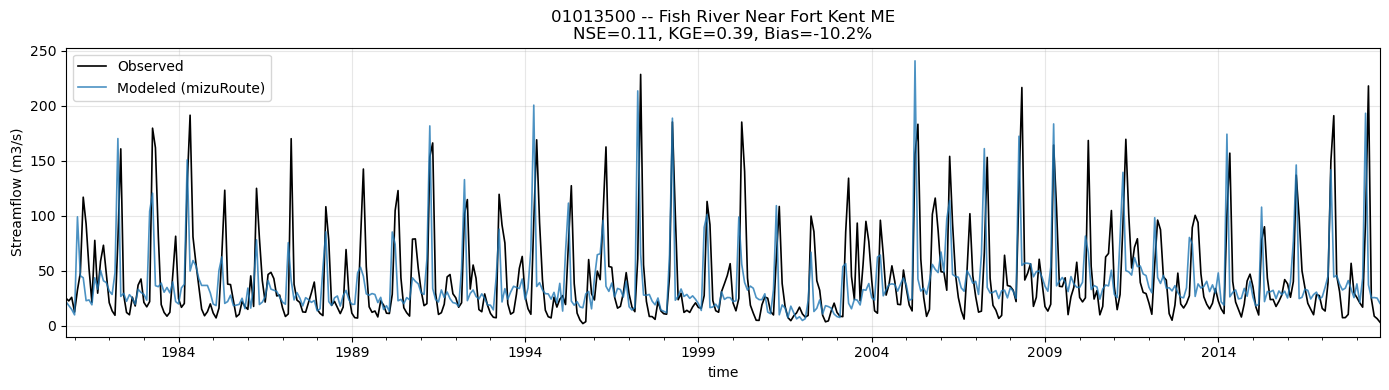


--- 06909000 (Missouri River at Boonville, MO) -- reach 74036914 ---
  NSE=-0.731  KGE=0.162  Bias=74.5%  n_months=456


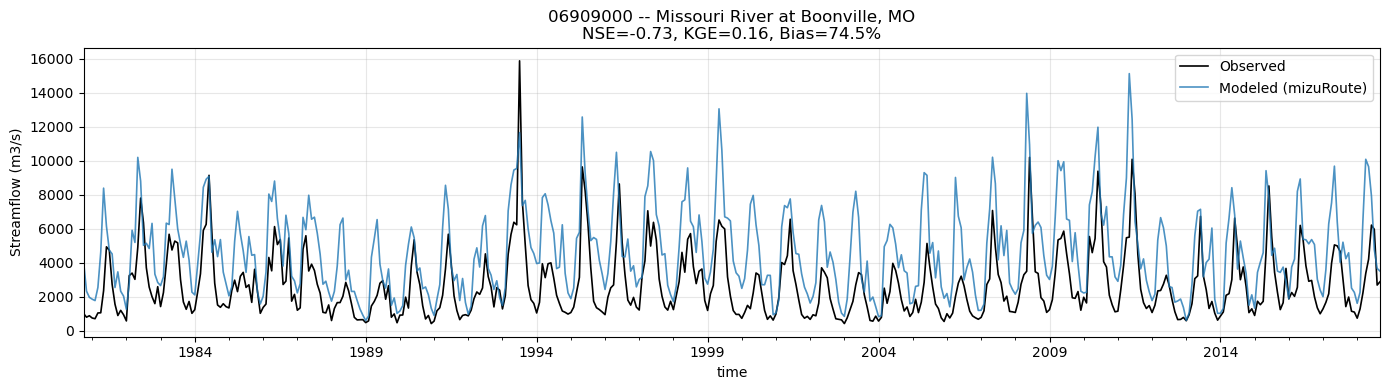


--- 06934500 (Missouri River at Hermann, MO) -- reach 74036886 ---
  NSE=-0.391  KGE=0.295  Bias=63.4%  n_months=456


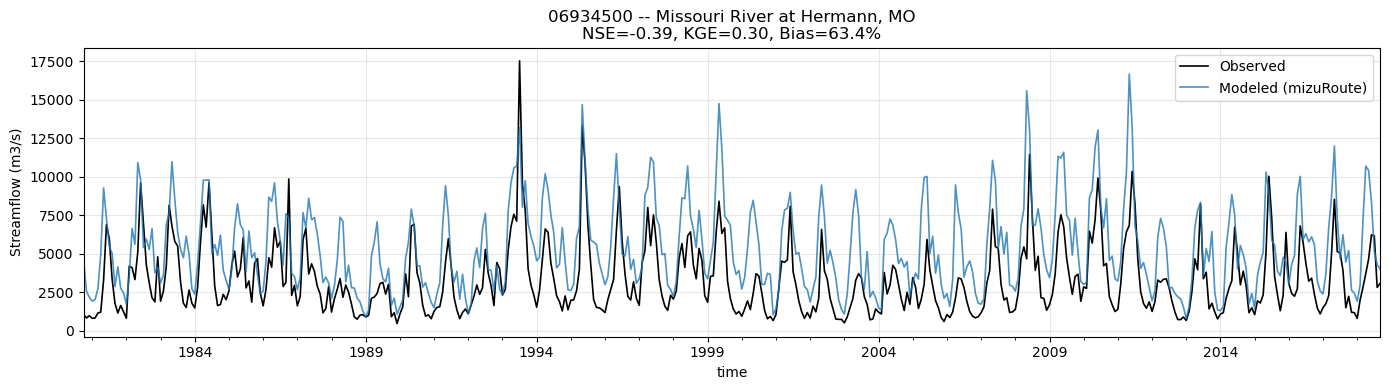


--- 06893000 (Missouri River at Kansas City, MO) -- reach 74036951 ---
  NSE=-1.236  KGE=0.009  Bias=84.2%  n_months=456


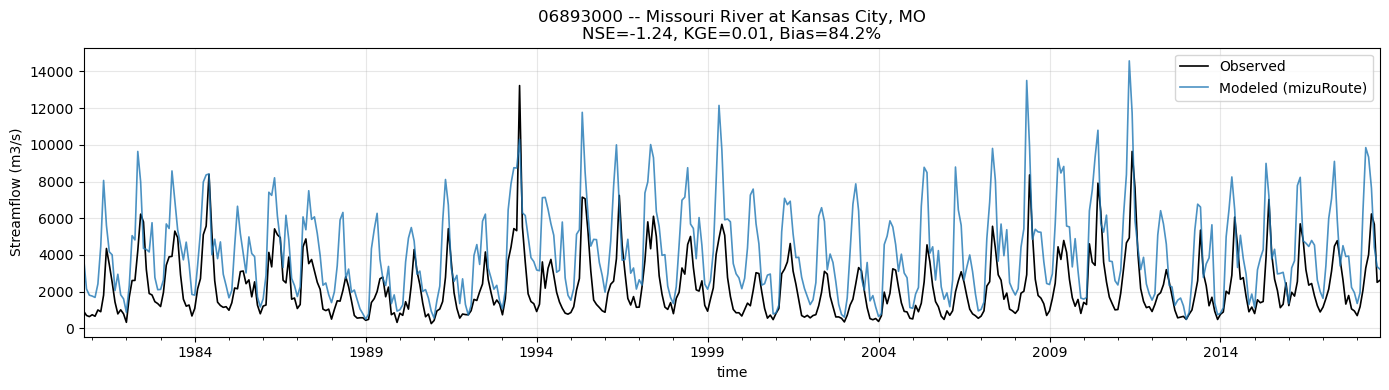


--- 06813500 (Missouri River at Rulo, NE) -- reach 74028912 ---
  NSE=-1.863  KGE=-0.154  Bias=89.0%  n_months=456


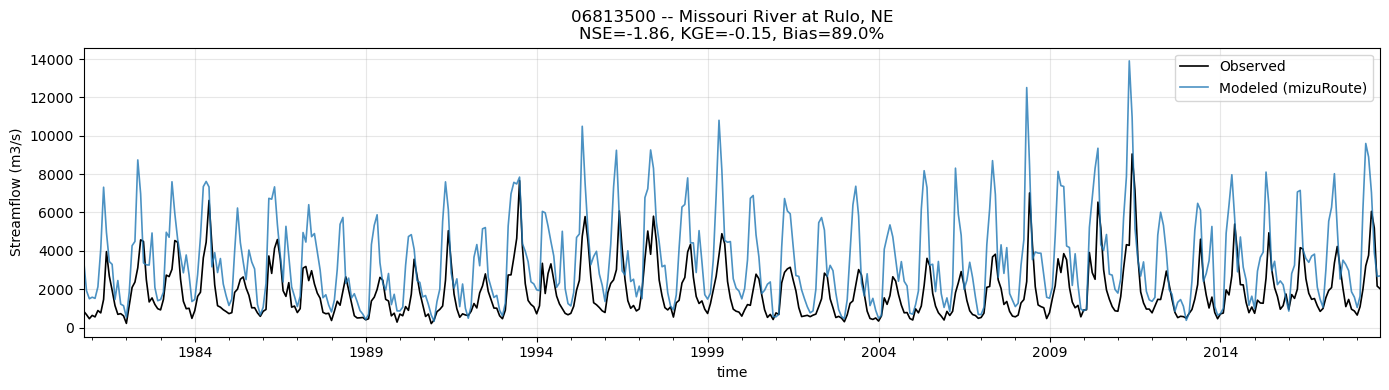


--- 06090800 (Missouri River at Fort Benton MT) -- reach 74001408 ---
  NSE=-8.403  KGE=-1.329  Bias=97.8%  n_months=424


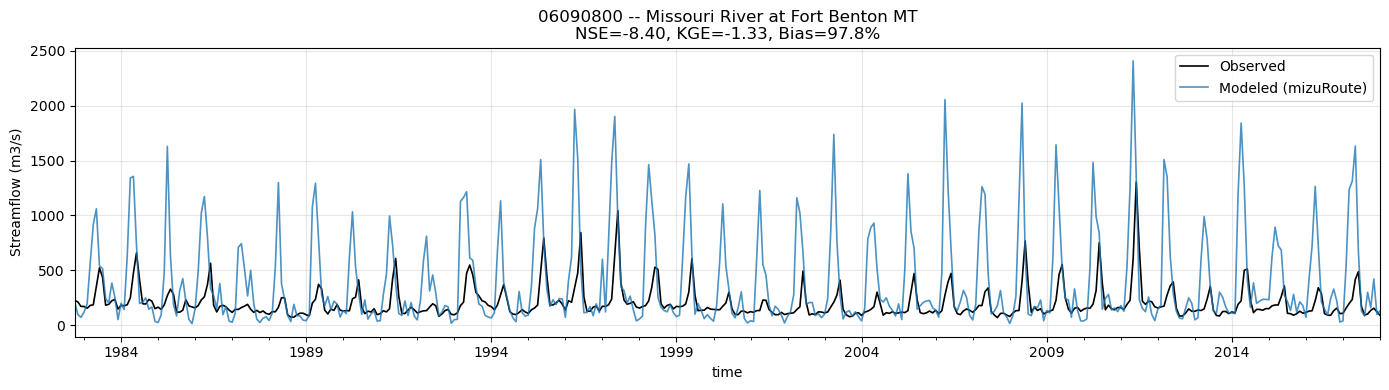


--- 05331000 (Mississippi River at St. Paul, MN) -- reach 74009182 ---
  NSE=0.295  KGE=0.380  Bias=19.7%  n_months=456


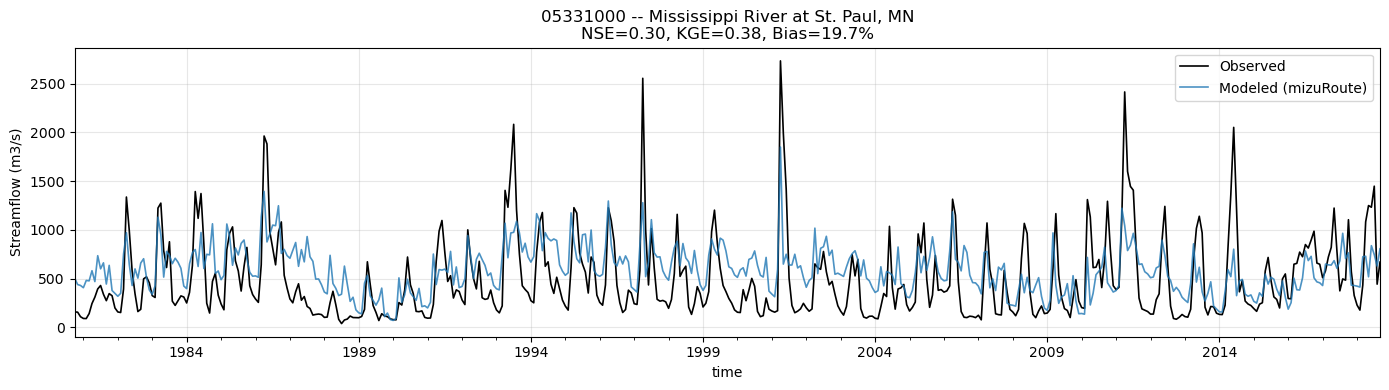


--- 05378500 (Mississippi River at Winona, MN) -- reach 74016318 ---
  NSE=0.371  KGE=0.526  Bias=13.3%  n_months=456


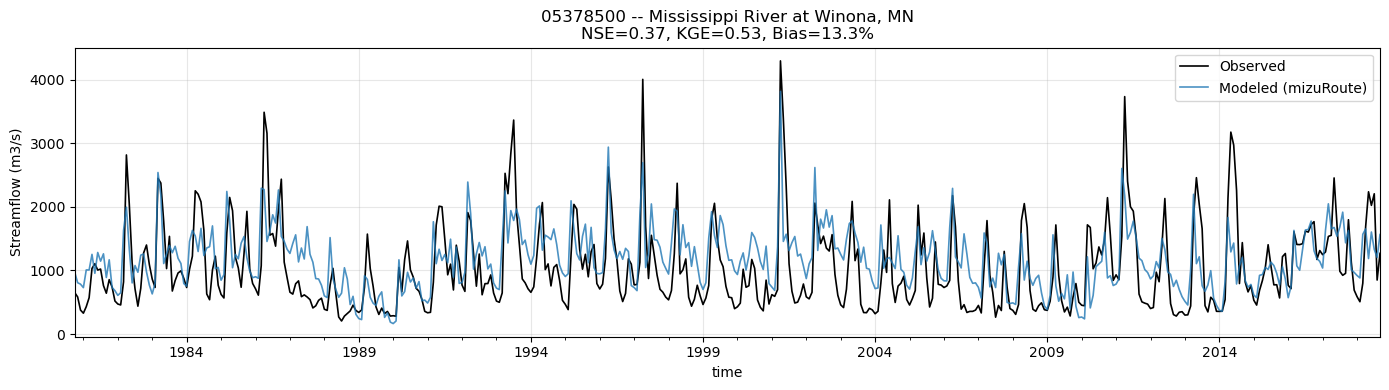


--- 03611500 (OHIO RIVER AT METROPOLIS, IL) -- reach 74045132 ---
  NSE=0.404  KGE=0.497  Bias=-1.8%  n_months=456


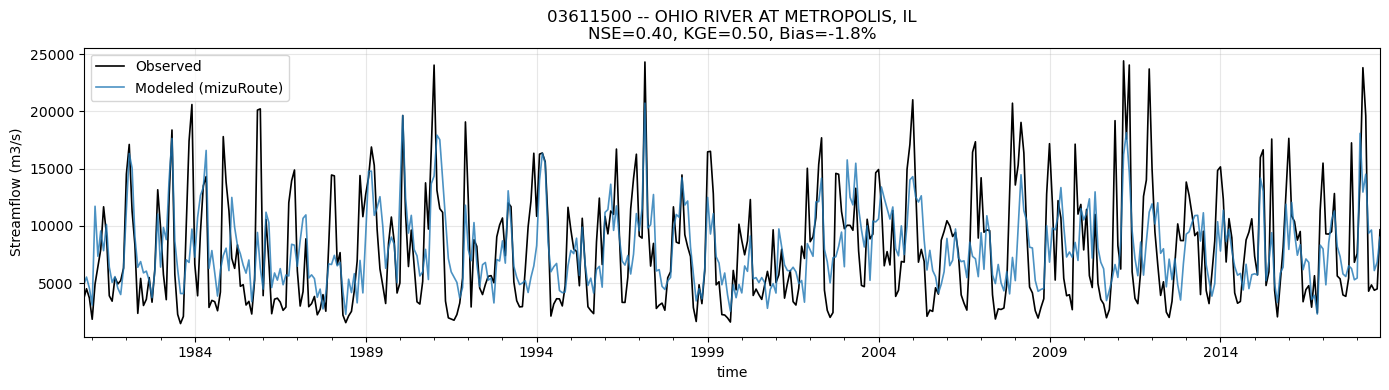


--- 03086000 (Ohio River at Sewickley, PA) -- reach 74029469 ---
  NSE=0.545  KGE=0.513  Bias=-24.0%  n_months=456


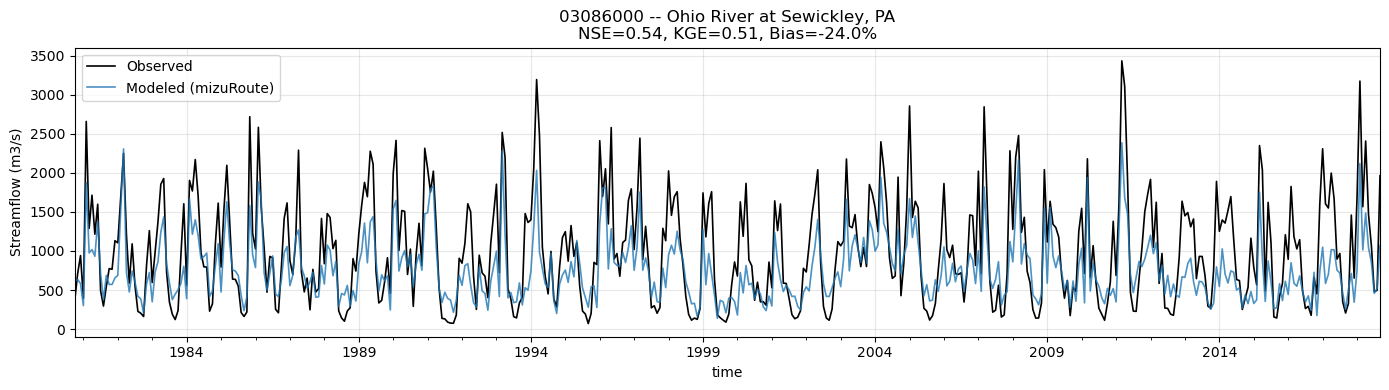

In [17]:
results_summary = []

for station_id in SELECTED_STATIONS:
    row = df_gauges[df_gauges["Station ID"] == station_id]
    if len(row) == 0:
        print(f"Station {station_id} not found in crosswalk, skipping.")
        continue
    row = row.iloc[0]
    reach_id = int(row["merit_reach_id"])
    gage_id = row["GAGE_ID"]
    long_name = row["Long_Name"]

    print(f"\n--- {station_id} ({long_name}) -- reach {reach_id} ---")

    modeled = get_modeled_monthly(reach_id)
    if modeled is None:
        print("  No modeled data found for this reachID.")
        continue

    observed = get_usgs_monthly(gage_id, MODEL_START, MODEL_END)
    if observed is None or observed.dropna().empty:
        print("  No observed data available.")
        continue

    combined = pd.concat([observed, modeled], axis=1).dropna()
    if len(combined) < 12:
        # FIX (diagnostic, new): show why, instead of just failing silently.
        # A real data-gap looks like non-overlapping date ranges below; an
        # alignment bug (already fixed above) would have shown both series
        # covering the same years but still failing to merge.
        print(f"  Not enough overlapping months to evaluate "
              f"({len(combined)} months after merge).")
        print(f"    modeled:  n={len(modeled)}, range {modeled.index.min()} to {modeled.index.max()}")
        print(f"    observed: n={len(observed)}, range {observed.index.min()} to {observed.index.max()}")
        continue

    nse_val = nse(combined["observed"], combined["modeled"])
    kge_val = kge(combined["observed"], combined["modeled"])
    bias_pct = 100 * (combined["modeled"].mean() - combined["observed"].mean()) / combined["observed"].mean()

    print(f"  NSE={nse_val:.3f}  KGE={kge_val:.3f}  Bias={bias_pct:.1f}%  n_months={len(combined)}")

    results_summary.append({
        "Station ID": station_id,
        "Long_Name": long_name,
        "merit_reach_id": reach_id,
        "GAGE_ID": gage_id,
        "NSE": nse_val,
        "KGE": kge_val,
        "Bias_pct": bias_pct,
        "n_months": len(combined),
    })

    fig, ax = plt.subplots(figsize=(14, 4))
    combined["observed"].plot(ax=ax, label="Observed", color="black", linewidth=1.2)
    combined["modeled"].plot(ax=ax, label="Modeled (mizuRoute)", color="tab:blue", linewidth=1.2, alpha=0.8)
    ax.set_ylabel("Streamflow (m3/s)")
    ax.set_title(f"{station_id} -- {long_name}\nNSE={nse_val:.2f}, KGE={kge_val:.2f}, Bias={bias_pct:.1f}%")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/{station_id}_monthly_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

## 7. Summary table across all evaluated gauges

In [18]:
df_summary = pd.DataFrame(results_summary)
df_summary = df_summary.sort_values("NSE", ascending=False)
df_summary.to_csv(f"{OUTPUT_DIR}/streamflow_eval_summary.csv", index=False)
print(f"Saved summary for {len(df_summary)} gauges to {OUTPUT_DIR}/streamflow_eval_summary.csv")
df_summary

Saved summary for 10 gauges to streamflow_eval_plots/streamflow_eval_summary.csv


,Station ID,Long_Name,merit_reach_id,GAGE_ID,NSE,KGE,Bias_pct,n_months
9,03086000,"Ohio River at Sewickley, PA",74029469,3086000,0.544960,0.512991,-24.042554,456
8,03611500,"OHIO RIVER AT METROPOLIS, IL",74045132,3611500,0.403716,0.496875,-1.787978,456
7,05378500,"Mississippi River at Winona, MN",74016318,5378500,0.371093,0.525594,13.285796,456
6,05331000,"Mississippi River at St. Paul, MN",74009182,5331000,0.295010,0.380289,19.704372,456
0,01013500,Fish River Near Fort Kent ME,72040863,1013500,0.114718,0.389728,-10.207476,456
2,06934500,"Missouri River at Hermann, MO",74036886,6934500,-0.390630,0.295080,63.381953,456
1,06909000,"Missouri River at Boonville, MO",74036914,6909000,-0.730598,0.161759,74.502004,456
3,06893000,"Missouri River at Kansas City, MO",74036951,6893000,-1.236107,0.009143,84.170722,456
4,06813500,"Missouri River at Rulo, NE",74028912,6813500,-1.862767,-0.154058,89.010719,456
5,06090800,Missouri River at Fort Benton MT,74001408,6090800,-8.403117,-1.328627,97.800152,424


In [19]:
missouri_stations = ["06909000", "06934500", "06893000", "06813500", "06090800"]

df_gauges[df_gauges["Station ID"].isin(missouri_stations)][
    ["Station ID", "Long_Name", "Type (naturalized, observed)", "source"]
]

,Station ID,Long_Name,"Type (naturalized, observed)",source
1519,06909000,"Missouri River at Boonville, MO",naturalized,USACE_Kansas City
1520,06934500,"Missouri River at Hermann, MO",naturalized,USACE_Kansas City
1521,06893000,"Missouri River at Kansas City, MO",naturalized,USACE_Kansas City
1522,06813500,"Missouri River at Rulo, NE",naturalized,USACE_Kansas City
1685,06090800,Missouri River at Fort Benton MT,naturalized,USACE_Omaha


## 8. Scaling up
To evaluate more gauges, add more Station IDs to `SELECTED_STATIONS` in section 5 and re-run sections 6-7. For a first broad pass, consider sampling a handful of gauges across different HUC02 regions (`df_gauges['HUC02'].unique()`) to cover diverse hydroclimate zones, rather than all 2311 at once.

## 9. Find specific named rivers (new)
Search the crosswalk by name instead of guessing which `reachID` corresponds to a given river. Useful for pulling a specific major basin (Missouri, Columbia, Colorado, etc.) for a hydrograph sanity check or eval, without relying on flow magnitude alone -- large rivers get split into many segments/distributaries near their mouths, so a plain top-N-by-flow search tends to resurface the same river repeatedly rather than finding distinct basins.

In [14]:
RIVER_NAMES_OF_INTEREST = ["Missouri", "Columbia", "Colorado", "Mississippi", "Ohio"]

for name in RIVER_NAMES_OF_INTEREST:
    matches = df_gauges[df_gauges["Long_Name"].str.contains(name, case=False, na=False)]
    print(f"\n{name}: {len(matches)} matching gauge(s)")
    if len(matches):
        display(matches[["Station ID", "GAGE_ID", "Long_Name", "merit_reach_id",
                          "Latitude", "Longitude"]].head(10))


Missouri: 24 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,Latitude,Longitude
808,07360200,7360200,Little Missouri River Near Langley AR,74063593,34.311667,-93.899722
1519,06909000,6909000,"Missouri River at Boonville, MO",74036914,38.980310,-92.745460
1520,06934500,6934500,"Missouri River at Hermann, MO",74036886,38.709810,-91.438500
1521,06893000,6893000,"Missouri River at Kansas City, MO",74036951,39.111720,-94.588140
1522,06813500,6813500,"Missouri River at Rulo, NE",74028912,40.052060,-95.421750
1523,06818000,6818000,"Missouri River at St. Joseph, MO",74037046,39.753250,-94.856830
1524,06895500,6895500,"Missouri River at Waverly, MO",74036935,39.215020,-93.515210
1668,06337000,6337000,Little Missouri Rv at Watford-WCND,74001303,47.589260,-103.252930
1685,06090800,6090800,Missouri River at Fort Benton MT,74001408,47.816870,-110.665780
1686,GARRISON,99901190,Missouri River at Garrison Dam,74004379,47.505300,-101.432430



Columbia: 1 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,Latitude,Longitude
1923,12363000,12363000,Columbia Falls,78013772,48.36194,-114.18389



Colorado: 23 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,Latitude,Longitude
1352,08158000,8158000,"Colorado Rv at Austin, TX",75011323,30.24465,-97.69445
1353,08126380,8126380,"Colorado Rv nr Ballinger, TX",75005324,31.71543,-100.02648
1354,08159200,8159200,"Colorado Rv at Bastrop, TX",75011315,30.10466,-97.31944
1355,08162500,8162500,"Colorado Rv nr Bay City, TX",75017594,28.97415,-96.01246
1358,08121000,8121000,"Colorado Rv at Colorado City, TX",75005477,32.39262,-100.87872
1359,08161000,8161000,"Colorado Rv at Columbus, TX",75011298,29.70635,-96.53692
1360,08124000,8124000,"Colorado Rv at Robert Lee, TX",75005337,31.88542,-100.48065
1363,08117995,8117995,"Colorado Rv nr Gail, TX",75005504,32.62872,-101.28540
1370,08136700,8136700,"Colorado Rv nr Stacy, TX",75005315,31.49377,-99.57395
1373,08147000,8147000,"Colorado Rv nr San Saba, TX",75011367,31.21795,-98.56448



Mississippi: 8 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,Latitude,Longitude
1998,WNBM5,99901630,Lake Winnibigoshish Dam at Mississippi River H...,74004695,47.43000,-94.05000
1999,FEDM5,99901640,Leech Lake Dam at Mississippi River Headwaters...,74005123,47.24747,-94.22184
2000,CRLM5,99901650,Mississippi River Headwaters Pine River Dam an...,74005297,46.66830,-94.11160
2001,GLLM5,99901660,Mississippi River Headwaters Gull Lake Dam,74005601,46.41109,-94.35358
2002,PKGM5,99901670,Pokegama Lake Dam at Mississippi River Headwat...,74004663,47.24830,-93.58660
2003,SDYM5,99901680,Big Sandy Lake Dam at Mississippi River Headwa...,74005368,46.78830,-93.32830
2231,05331000,5331000,"Mississippi River at St. Paul, MN",74009182,44.94444,-93.08811
2233,05378500,5378500,"Mississippi River at Winona, MN",74016318,44.05552,-91.63765



Ohio: 3 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,Latitude,Longitude
379,03237500,3237500,Ohio Brush Creek Near West Union OH,74038888,38.803684,-83.421023
1528,03611500,3611500,"OHIO RIVER AT METROPOLIS, IL",74045132,37.147550,-88.740890
1789,03086000,3086000,"Ohio River at Sewickley, PA",74029469,40.549190,-80.205610


### 9b. Name matching alone isn't reliable -- filter by HUC02 too
Plain substring search on `Long_Name` pulled in the wrong river: all 23 "Colorado" matches above are the Colorado River in **Texas** (HUC02 12), not the western Colorado River through the Grand Canyon (HUC02 14/15) -- and "Columbia" matched a town name, missing the real Columbia River (HUC02 17) mainstem gauges entirely. Combine name with HUC02 to disambiguate.

Reference HUC02 regions: 10 = Missouri, 14/15 = Upper/Lower Colorado, 17 = Pacific Northwest (Columbia), 05/06/08 = Ohio/Tennessee/Lower Mississippi, 07 = Upper Mississippi.

In [15]:
if "HUC02" in df_gauges.columns:
    TARGET_BASINS = {
        "Missouri":    {"huc02": ["10"]},
        "Colorado":    {"huc02": ["14", "15"]},
        "Columbia":    {"huc02": ["17"]},
        "Mississippi": {"huc02": ["05", "06", "07", "08"]},
    }
    for name, spec in TARGET_BASINS.items():
        matches = df_gauges[
            df_gauges["Long_Name"].str.contains(name, case=False, na=False)
            & df_gauges["HUC02"].astype(str).str.zfill(2).isin(spec["huc02"])
        ]
        print(f"\n{name} (HUC02 in {spec['huc02']}): {len(matches)} matching gauge(s)")
        if len(matches):
            display(matches[["Station ID", "GAGE_ID", "Long_Name", "merit_reach_id",
                              "HUC02", "Latitude", "Longitude"]].head(10))
else:
    print("df_gauges has no 'HUC02' column -- check the actual column name "
          "(df_gauges.columns.tolist()) and adjust above.")


Missouri (HUC02 in ['10']): 23 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,HUC02,Latitude,Longitude
1519,06909000,6909000,"Missouri River at Boonville, MO",74036914,10,38.98031,-92.74546
1520,06934500,6934500,"Missouri River at Hermann, MO",74036886,10,38.70981,-91.43850
1521,06893000,6893000,"Missouri River at Kansas City, MO",74036951,10,39.11172,-94.58814
1522,06813500,6813500,"Missouri River at Rulo, NE",74028912,10,40.05206,-95.42175
1523,06818000,6818000,"Missouri River at St. Joseph, MO",74037046,10,39.75325,-94.85683
1524,06895500,6895500,"Missouri River at Waverly, MO",74036935,10,39.21502,-93.51521
1668,06337000,6337000,Little Missouri Rv at Watford-WCND,74001303,10,47.58926,-103.25293
1685,06090800,6090800,Missouri River at Fort Benton MT,74001408,10,47.81687,-110.66578
1686,GARRISON,99901190,Missouri River at Garrison Dam,74004379,10,47.50530,-101.43243
1687,06115200,6115200,Missouri River at Landusky,74001337,10,47.63072,-108.68463



Colorado (HUC02 in ['14', '15']): 10 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,HUC02,Latitude,Longitude
2282,09072500,9072500,"Colorado River at Glenwood Springs, CO",77006258,14,39.54998,-107.32089
2283,09095500,9095500,"Colorado River near Cameo, CO",77006205,14,39.23915,-108.26619
2288,09180500,9180500,"Colorado River near Cisco, UT",77013368,14,38.81054,-109.29345
2301,09380000,9380000,"Colorado River at Lees Ferry, AZ",77020709,14,36.86433,-111.58787
2303,09402000,9402000,"Little Colorado River near Cameron, AZ",77020864,15,35.92638,-111.56737
2304,09402500,9402500,"Colorado River near Grand Canyon, AZ",77020686,15,36.10137,-112.08628
2306,09421500,9421500,"Colorado River below Hoover Dam, AZ-NV",77020615,15,36.01526,-114.73859
2307,09423000,9423000,"Colorado River below Davis Dam, AZ-NV",77020583,15,35.19167,-114.57219
2309,09427520,9427520,"Colorado River below Parker Dam, AZ-CA",77027131,15,34.29558,-114.14023
2310,09429490,9429490,"Colorado River above Imperial Dam, AZ",77032225,15,32.88494,-114.46811



Columbia (HUC02 in ['17']): 1 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,HUC02,Latitude,Longitude
1923,12363000,12363000,Columbia Falls,78013772,17,48.36194,-114.18389



Mississippi (HUC02 in ['05', '06', '07', '08']): 8 matching gauge(s)


,Station ID,GAGE_ID,Long_Name,merit_reach_id,HUC02,Latitude,Longitude
1998,WNBM5,99901630,Lake Winnibigoshish Dam at Mississippi River H...,74004695,7,47.43000,-94.05000
1999,FEDM5,99901640,Leech Lake Dam at Mississippi River Headwaters...,74005123,7,47.24747,-94.22184
2000,CRLM5,99901650,Mississippi River Headwaters Pine River Dam an...,74005297,7,46.66830,-94.11160
2001,GLLM5,99901660,Mississippi River Headwaters Gull Lake Dam,74005601,7,46.41109,-94.35358
2002,PKGM5,99901670,Pokegama Lake Dam at Mississippi River Headwat...,74004663,7,47.24830,-93.58660
2003,SDYM5,99901680,Big Sandy Lake Dam at Mississippi River Headwa...,74005368,7,46.78830,-93.32830
2231,05331000,5331000,"Mississippi River at St. Paul, MN",74009182,7,44.94444,-93.08811
2233,05378500,5378500,"Mississippi River at Winona, MN",74016318,7,44.05552,-91.63765
